In [5]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, BayesianRidge, PoissonRegressor, Ridge, SGDClassifier, HuberRegressor, QuantileRegressor, Lasso, ElasticNet
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)  
pd.set_option('display.max_columns', None)  
pd.set_option('display.expand_frame_repr', False)

## Utility Functions

In [6]:
def load_node_profile(node):
    filepath = f'../../tool/infrastructure-profiler/profiles/{node}.csv'

    with open(filepath) as f:
        data = f.readlines()[1].split(',')

    return {
        'ram': int(data[1].strip()),
        'cores': int(data[2].strip()),
        'io_read': float(data[3].strip()),
        'io_write': float(data[4].strip()),
        'sysbench': float(data[5].strip()),
        'z7b': float(data[6].strip()),
        'bench_time': float(data[7].strip())
    }

def combine_df(input_df, trace_df):
    rows = []

    for name, group in input_df.groupby('name'):
        no_files = str(len(group))
        filepaths = group['path']
        paths = ','.join([filepath.split('/')[-1].split('.')[-1] for filepath in filepaths])
        total_size = group['size'].sum() / 1073741824  # convert from B to GiB

        if len(trace_df[trace_df['name'] == name]) > 0:
            task_record = trace_df[trace_df['name'] == name].iloc[0]
            task_realtime = task_record['realtime']
            task_difftime = task_record['complete'] - task_record['start']
            task_memory = task_record['memory'] / 1073741824  # convert from B to GiB
            if task_difftime > (1.2 * task_realtime):
                task_runtime = task_realtime
            else:
                task_runtime = task_realtime
            short_name = task_record['name'].split(':')[-2] + ':' + task_record['name'].split(':')[-1].split(' ')[0]
            row = [task_record['task_id'], task_record['name'], task_record['%cpu'], 
                task_record['start'], task_record['complete'], task_runtime, 
                no_files, paths, total_size, short_name, task_record['hostname'], task_memory]
            rows.append(row) 
        else:
            print('err:', name)

    combined = pd.DataFrame(rows, columns=['id', 'name', '%cpu', 'start', 'complete', 'runtime', 'no_files', 'files', 'input_gib', 'short_name', 'hostname', 'memory'])
    return combined

def load_profiling_runs(node, workflows, samples, node_profiles):
    node_profile = node_profiles[node]
    runs = {}

    for workflow, samples in zip(workflows, samples):
        runs[workflow] = {}

        for sample in samples:
            sample_dir = f'{node}/{workflow}/{sample}/'
            input_df = pd.read_csv(sample_dir + 'input.csv', sep=';')
            trace_df = pd.read_csv(sample_dir + 'trace.csv')
            runs[workflow][sample] = combine_df(input_df, trace_df)

    return (node_profile, runs)

def load_workflow_execution(cluster, workflow, iteration):
    execution_dir = f'../{cluster}/{workflow}/{iteration}/'
    input_df = pd.read_csv(execution_dir + 'input.csv', sep=';')
    trace_df = pd.read_csv(execution_dir + 'trace.csv')
    return combine_df(input_df, trace_df)

def load_ichnos_trace(cluster, workflow, iteration, gov):
    short_cluster = cluster.split('-')[0]
    trace_loc = f'../{cluster}/{workflow}/ichnos/{short_cluster}-{workflow}-{iteration}-1-{gov}-trace.csv'
    return pd.read_csv(trace_loc)

def process_ichnos_summary(raw):
    core_total_energy = float(raw[7].split(': ')[-1][:-3])
    mem_dynamic_energy = float(raw[9].split(': ')[-1][:-3])
    mem_static_energy = float(raw[15].split(': ')[-1][:-3])
    return {
        'core_total': core_total_energy, 
        'mem_dynamic': mem_dynamic_energy, 
        'mem_static': mem_static_energy, 
        'total': core_total_energy + mem_dynamic_energy + mem_static_energy
    } 

def load_ichnos_summary(cluster, workflow, iteration, gov):
    short_cluster = cluster.split('-')[0]
    with open(f'../{cluster}/{workflow}/ichnos/{short_cluster}-{workflow}-{iteration}-1-{gov}-summary.txt', 'r') as file:
        raw = file.readlines()
    raw = [line.strip() for line in raw]
    return process_ichnos_summary(raw)

def load_rapl_summary(cluster, workflow, iteration):
    rapl_vals = pd.read_csv(f'../{cluster}/{workflow}-runs.csv')
    return rapl_vals.iloc[[iteration - 1]]

def load_power_model(node, setting=''):
    if setting != '':
        filename = f'{setting}-model.txt'
    else: 
        filename = 'model.txt'

    with open(f'../../tool/infrastructure-profiler/raw/{node}/{filename}', 'r') as f:
        data = [line.strip() for line in f.readlines()[1:]]

    coeff = float(data[0].split(',')[0][2:].strip())
    inter = float(data[0].split(',')[1][:-2].strip())
    draw = float(data[1].split(':')[1].strip())

    if draw == 0:
        draw = 0.392

    return (coeff, inter, draw)

def get_task_data_from_experiment(task_name, experiment):
    task_data = experiment[experiment['short_name'] == task_name]
    key_data = task_data[['input_gib', 'runtime', '%cpu']]
    key_data.columns = ['data', 'time', 'usage']
    key_data.reset_index().drop('index', axis=1)
    return key_data

def get_error(predicted, actual):
    return abs(actual - predicted) / actual * 100

In [7]:
class MedianModel:
    def __init__(self, median):
        self.median = median
    
    def predict(self, x):
        x = np.asarray(x)
        value = x.shape[0]
        return np.full(value, self.median)

## Setup Data

In [8]:
# Constants
HU = 'hu'
HU_40 = 'hu-c40'
HU_42 = 'hu-c42'
HU_44 = 'hu-c44'
HU_45 = 'hu-c45'
GPG = 'gpg'
GPG_13 = 'gpgnode-13'
GPG_14 = 'gpgnode-14'
GPG_15 = 'gpgnode-15'
GPG_16 = 'gpgnode-16'
GPG_17 = 'gpgnode-17'
GPG_18 = 'gpgnode-18'
GPG_22 = 'gpgnode-22'
AWS = 'aws'
AWS_m5_4xl = 'aws-m5-4xl'
AWS_c5d = 'aws-metal-c5d'
GCP_n2 = 'gcp-n2'
wfs = {
    GPG: ['rnaseq', 'chipseq', 'nanoseq', 'atacseq'], 
    HU: ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
}
VR = 'VR'
RF = 'RandomForest'
LR = 'LinearRegression'
BR = 'BayesianRidge'
PR = 'PoissonRegressor'
GBR = 'GradientBoostingRegressor'
RIDGE = 'Ridge'
SGD = 'StochasticGradientDescent'
HR = 'HuberRegressor'
QR = 'QuantileRegressor'
LASSO = 'Lasso'
ENET = 'ElasticNet'
paper_nodes = {
    AWS_m5_4xl: 'minerva',
    AWS_c5d: 'diana', 
    GPG_18: 'neptune',
    HU_40: 'jupiter'
}
paper_cluster_nodes = {
    GPG: 'neptune',
    HU: 'jupiter'
}

In [9]:
# Node Profiles + Power Models 
nodes = [GPG_13, GPG_14, GPG_15, GPG_16, GPG_17, GPG_18, GPG_22, HU_40, HU_42, AWS_c5d, HU_44, HU_45, AWS_m5_4xl]
node_profiles = {}

for node in nodes:
    profile = load_node_profile(node)
    node_profiles[node] = profile

nodes_by_host = {
    'hu-worker-c40': HU_40,
    'hu-worker-c42': HU_42,
    'hu-worker-c44': HU_44,
    'hu-worker-c45': HU_45
}

gov_by_workflow = {
    GPG: {
        "rnaseq": "ondemand_linear",
        "chipseq": "ondemand_linear",
        "nanoseq": "ondemand_linear",
        "atacseq": "ondemand_linear"
    },
    HU: {
        "rnaseq": "schedutil_linear",
        "chipseq": "schedutil_linear",
        "rangeland": "schedutil_linear",
        "sarek": "schedutil_linear",
        "nanoseq": "performance_linear",
        "atacseq": "performance_linear"
    }
}

In [10]:
# Workflow Executions 
wf_executions = {}

for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    wf_executions[cluster] = {}
    for wf in wfs[cluster]:
        wf_executions[cluster][wf] = {}
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration] = {}
            wf_executions[cluster][wf][iteration]['run'] = load_workflow_execution(cluster_path, wf, iteration)

In [11]:
# Workflow RAPL Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration]['rapl'] = load_rapl_summary(cluster_path, wf, iteration)

In [12]:
# Workflow Ichnos Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration]['ichnos'] = load_ichnos_summary(cluster_path, wf, iteration, gov_by_workflow[cluster][wf])

In [13]:
# Join Workflow Traces with Ichnos Traces 
def add_energy_with_task_id(run, ichnos):
    combined = pd.merge(run, ichnos[['id', 'core_kwh', 'mem_kwh']], on='id').drop_duplicates()
    return combined[['id', 'name', '%cpu', 'start', 'complete', 'runtime', 'no_files', 'files', 'input_gib', 'short_name', 'hostname', 'core_kwh', 'mem_kwh', 'memory']]

# Workflow Ichnos Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            run = wf_executions[cluster][wf][iteration]['run']
            ichnos_trace = load_ichnos_trace(cluster_path, wf, iteration, gov_by_workflow[cluster][wf])
            df_with_energy = add_energy_with_task_id(run, ichnos_trace)
            wf_executions[cluster][wf][iteration]['run'] = df_with_energy

In [14]:
# Compare RAPL Total to Ichnos Total
gu_socket = {'rnaseq': '_2', 'chipseq': '_2', 'nanoseq': 'both', 'atacseq': 'both'}
hu_socket = {'rnaseq': '', 'chipseq': '', 'nanoseq': '', 'atacseq': ''}

for cluster, cluster_path, socket in zip([GPG, HU], ['gu-cluster', 'hu-cluster'], [gu_socket, hu_socket]):
    print('===', cluster, '===')
    for wf in wfs[cluster]:
        all_ichnos = []
        all_rapl = []

        for iteration in range(1, 4):
            ichnos_total = wf_executions[cluster][wf][iteration]['ichnos']['total']
            ichnos_core = wf_executions[cluster][wf][iteration]['ichnos']['core_total']
            ichnos_mem = wf_executions[cluster][wf][iteration]['ichnos']['mem_dynamic'] + wf_executions[cluster][wf][iteration]['ichnos']['mem_static']

            rapl_socket = socket[wf]
            if rapl_socket == 'both':
                rapl_core = wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg_2'].iloc[0]

                if wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram_2'].iloc[0] > wf_executions[cluster][wf][iteration]['rapl'][f'dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'dram_2'].iloc[0]:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'dram_2'].iloc[0]
                else:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'active_dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'active_dram_2'].iloc[0]
            else:
                rapl_core = wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg{rapl_socket}'].iloc[0]

                if wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram{rapl_socket}'].iloc[0] > wf_executions[cluster][wf][iteration]['rapl'][f'dram{rapl_socket}'].iloc[0]:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'dram{rapl_socket}'].iloc[0]
                else:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'active_dram{rapl_socket}'].iloc[0]

            rapl_total = rapl_core + rapl_mem
            wf_executions[cluster][wf][iteration]['rapl']['core'] = rapl_core
            wf_executions[cluster][wf][iteration]['rapl']['mem'] = rapl_mem
            core_error = abs(rapl_core - ichnos_core) / rapl_core * 100
            mem_error = abs(rapl_mem - ichnos_mem) / rapl_mem * 100
            total_error = abs(rapl_total - ichnos_total) / rapl_total * 100

            #print(f'{wf}-{iteration} ichnos: {ichnos_total:.2f}kWh rapl: {rapl_total:.2f}kWh error {total_error:.2f}%')
            all_ichnos.append(ichnos_total)
            all_rapl.append(rapl_total)
        avg_ichnos = np.mean(all_ichnos)
        avg_rapl = np.mean(all_rapl)

        print(f'{wf} i: {avg_ichnos:.2f}kWh, r: {avg_rapl:.2f}kWh, {get_error(avg_ichnos, avg_rapl):.2f}%')

=== gpg ===
rnaseq i: 1.52kWh, r: 1.43kWh, 6.99%
chipseq i: 2.00kWh, r: 1.90kWh, 5.64%
nanoseq i: 0.88kWh, r: 0.98kWh, 10.56%
atacseq i: 1.43kWh, r: 1.53kWh, 6.38%
=== hu ===
rnaseq i: 2.28kWh, r: 2.54kWh, 10.20%
chipseq i: 4.68kWh, r: 5.16kWh, 9.22%
nanoseq i: 0.42kWh, r: 0.51kWh, 16.86%
atacseq i: 0.61kWh, r: 0.67kWh, 9.95%


In [15]:
# Load workflow profiling runs
wf_profiles = {}
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_g', 'sample_h', 'sample_i', 'sample_j'], 
           ['sample_k', 'sample_l', 'sample_m', 'sample_n', 'sample_o'], 
           ['sample_p', 'sample_q', 'sample_r', 'sample_s', 'sample_t']]
wfs = ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
# HU_40
profile, runs = load_profiling_runs(HU_40, wfs, samples, node_profiles)
wf_profiles[HU_40] = { 'node_profile': profile, 'executions': runs, 'power_model': load_power_model(HU_40, 'schedutil') }
# HU_42
wf_profiles[HU_42] = { 'node_profile': profile, 'power_model': load_power_model(HU_42, 'schedutil') }
# HU_44
wf_profiles[HU_44] = { 'node_profile': profile, 'power_model': load_power_model(HU_44, 'schedutil') }
# HU_45
wf_profiles[HU_45] = { 'node_profile': profile, 'power_model': load_power_model(HU_45, 'schedutil') }
# gpgnode-13
wf_profiles[GPG_13] = { 'node_profile': node_profiles[GPG_13], 'power_model': load_power_model(GPG_13, 'ondemand') }
# gpgnode-14
wf_profiles[GPG_14] = { 'node_profile': node_profiles[GPG_14], 'power_model': load_power_model(GPG_14, 'ondemand') }
# gpgnode-15
wf_profiles[GPG_15] = { 'node_profile': node_profiles[GPG_15], 'power_model': load_power_model(GPG_15, 'ondemand') }
# gpgnode-16
wf_profiles[GPG_16] = { 'node_profile': node_profiles[GPG_16], 'power_model': load_power_model(GPG_16, 'ondemand') }
# gpgnode-17
wf_profiles[GPG_17] = { 'node_profile': node_profiles[GPG_17], 'power_model': load_power_model(GPG_17, 'ondemand') }
# gpgnode-18
profile, runs = load_profiling_runs(GPG_18, wfs, samples, node_profiles)
wf_profiles[GPG_18] = { 'node_profile': node_profiles[GPG_18], 'executions': runs, 'power_model': load_power_model(GPG_18, 'ondemand') }
# AWS metal c5d
profile, runs = load_profiling_runs(AWS_c5d, wfs, samples, node_profiles)
wf_profiles[AWS_c5d] = { 'node_profile': node_profiles[AWS_c5d], 'executions': runs, 'power_model': load_power_model(AWS_c5d) }
profile, runs = load_profiling_runs(AWS_m5_4xl, wfs, samples, node_profiles)
wf_profiles[AWS_m5_4xl] = { 'node_profile': node_profiles[AWS_m5_4xl], 'executions': runs} # no power model it's a VM

In [16]:
# @Vasilis: profiling data -- mini executions using downsampled data on a single node
for node in wf_profiles.keys():
    if 'executions' in wf_profiles[node]:
        print(wf_profiles[node]['executions']['rnaseq'])

for cluster, workflows in zip([HU, GPG], [['rnaseq', 'chipseq', 'nanoseq'], ['rnaseq', 'chipseq', 'nanoseq']]):
    for workflow in workflows:
        print(wf_executions[cluster][workflow][1]['run'])  # run 1, 2 and 3 

{'sample_a':     id                                               name   %cpu          start       complete  runtime no_files                                              files  input_gib                                         short_name hostname  memory
0    2  NFCORE_RNASEQ:PREPARE_GENOME:CUSTOM_GETCHROMSI...   99.9  1769782517205  1769782525838     8000        1                                                 fa   2.931141                PREPARE_GENOME:CUSTOM_GETCHROMSIZES        -     6.0
1    1  NFCORE_RNASEQ:PREPARE_GENOME:GTF_FILTER (genom...   99.8  1769782517204  1769782532517    14000        2                                             gtf,fa   3.784320                          PREPARE_GENOME:GTF_FILTER        -     6.0
2    6  NFCORE_RNASEQ:PREPARE_GENOME:MAKE_TRANSCRIPTS_...  100.1  1769782532617  1769782576731    42250        2                                             gtf,fa   3.711849              PREPARE_GENOME:MAKE_TRANSCRIPTS_FASTA        -    72.0
3    7  NFCORE_

## Evaluation

In [62]:
# Augur Functions
def find_closest_key(task_name, dictionary):
    task_end = task_name.split(':')[-1]
    match = ''

    for key in list(dictionary.keys()):
        key_end = key.split(':')[-1]
        if key_end == task_end:
            match = key

    return match

def compute_active_time_per_host(execution):
    tasks_by_host = {}

    for _, record in execution.iterrows():
        host = record['hostname']
        start_ts = record['start']
        end_ts = record['complete']

        if host in tasks_by_host:
            tasks_by_host[host].append((start_ts, end_ts))
        else:
            tasks_by_host[host] = [(start_ts, end_ts)]

    active_time_by_host = {}

    for host, intervals in tasks_by_host.items():
        if not intervals:
            continue

        intervals.sort(key=lambda x: x[0])  # sort by start timestamp
        merged = []
        current_start, current_end = intervals[0]

        for start, end in intervals[1:]:
            if start <= current_end:  # overlap or contiguous
                current_end = max(current_end, end)
            else:
                merged.append((current_start, current_end))
                current_start, current_end = start, end
        merged.append((current_start, current_end))

        total_ms: float = sum(end - start for start, end in merged)
        active_time_by_host[host] = total_ms / 1000 / 3600  # return time in hours

    return active_time_by_host

def get_translation_factor(local_profile, target_profile):
    local_write_val = local_profile['io_write'] / local_profile['ram']
    local_read_val = local_profile['io_read'] / local_profile['ram']
    target_write_val = target_profile['io_write'] / target_profile['ram']
    target_read_val = target_profile['io_read'] / target_profile['ram']
    cpu_part = (0.5 * (target_profile['z7b'] / local_profile['z7b'])) 
    + (0.5 * (local_profile['sysbench'] / target_profile['sysbench']))
    mem_part = (0.5 * (local_write_val / target_write_val)) + (0.5 * (local_read_val / target_read_val))

    if local_profile['cores'] != target_profile['cores']:
        target = (0.5 * (0.5 * cpu_part) + (0.5 * mem_part)) + (0.5 * (local_profile['cores'] / target_profile['cores']))
    else:
        target = (0.5 * cpu_part) + (0.5 * mem_part)

    return target

def get_lotaru_translation_factor(local_profile, target_profile):
    local_write_val = local_profile['io_write'] / local_profile['ram']
    target_write_val = target_profile['io_write'] / target_profile['ram']
    cpu_score = local_profile['sysbench'] / target_profile['sysbench']
    io_score = local_write_val / target_write_val
    return (cpu_score + io_score) / 2

def get_task_data_from_cluster_runs(runs, exclude_workflow, variant=False):
    all_task_data = {}

    for workflow in runs.keys():
        if workflow == exclude_workflow and variant:
            tasks = runs[workflow][1]['run']['short_name'].unique()
            for task in tasks:
                experiment_data = get_task_data_from_experiment(task, runs[workflow][1]['run'])
                all_task_data[task] = experiment_data
            continue
        elif workflow == exclude_workflow:
            continue

        iterations = range(1, 4)
        tasks = runs[workflow][iterations[0]]['run']['short_name'].unique()

        for task in tasks:
            task_data = pd.DataFrame(columns=['data', 'time', 'usage'], dtype='float64')
            for iteration in iterations:
                experiment_data = get_task_data_from_experiment(task, runs[workflow][iteration]['run'])
                task_data = pd.concat([task_data, experiment_data])

            all_task_data[task] = task_data

    return all_task_data

def get_model(model_type):
    if model_type == BR:
        model = BayesianRidge(fit_intercept=True)
    elif model_type == GBR:
        model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)
    elif model_type == VR:
        model = SVR()
    elif model_type == RF:
        model = RandomForestRegressor()
    elif model_type == PR:
        model = PoissonRegressor(fit_intercept=True)
    elif model_type == RIDGE:
        model = Ridge(fit_intercept = True)
    elif model_type == SGD:
        model = SGDClassifier(fit_intercept=True)
    elif model_type == QR:
        model = QuantileRegressor(fit_intercept=True)
    elif model_type == HR:
        model = HuberRegressor(fit_intercept=True)
    elif model_type == LASSO:
        model = Lasso(fit_intercept=True)
    elif model_type == ENET:
        model = ElasticNet(alpha=0.5, fit_intercept=True)
    else:
        model = LinearRegression()

    return model

In [18]:
# @Vasilis -- latest version of prediction model combining profiling runs with workflow executions (of other workflows)
def train_task_prediction_model(training_data, model_type, backup_models, reflector):
    variance = np.std(training_data['data'])
    pearson = np.corrcoef(training_data['data'].to_numpy(), training_data['time'].to_numpy())[0, 1]

    # case 1: no relationship
    if np.isnan(pearson) or pearson < 0.5:  
        model = MedianModel(np.median(training_data['time'].to_numpy())) 
        model_type = 'Median'  # GBR
    # case 2: weak linear relationship
    elif pearson < 0.75:
        model = get_model(backup_models[0])
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values) 
        model_type = 'Weak Linear Rel.'
    # case 3: low variance
    elif variance < 0.04:
        model = get_model(backup_models[1])
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values) 
        model_type = 'Low Variance'
    # case 4: strong linear relationship
    else:
        model = get_model(model_type)
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values) 
        model_type = model_type

    if reflector:
        model_type += '**'

    return (model, model_type, variance, pearson)


def create_prediction_model_with_reflections(profiling_runs, model_type, cluster_runs, exclude_workflow, local_profile, target_profile, backup_models, reflector=True, variant=False, lotaru=False):
    factor = get_translation_factor(local_profile, target_profile)
    if lotaru:
        factor = get_lotaru_translation_factor(local_profile, target_profile)
    models, reflector_data = {}, {}

    if reflector:
        reflector_data = get_task_data_from_cluster_runs(cluster_runs, exclude_workflow, variant)

    for workflow in profiling_runs.keys():
        models[workflow] = {}
        samples = list(profiling_runs[workflow].keys()) 
        tasks = profiling_runs[workflow][samples[0]]['short_name'].unique() 

        for task in tasks:
            task_profiling_data = pd.DataFrame(columns=['data', 'time', 'usage'], dtype='float64')
            for sample in samples: 
                experiment_data = get_task_data_from_experiment(task, profiling_runs[workflow][sample])
                task_profiling_data = pd.concat([task_profiling_data, experiment_data])

            models[workflow][task] = {}
            models[workflow][task]['data_profiling'] = task_profiling_data

            # @Vasilis where reflector data is added to the task data
            if task in reflector_data.keys():
                tmp_reflector_data = reflector_data.pop(task)
                tmp_reflector_data['time'] = tmp_reflector_data['time'] / factor
                models[workflow][task]['data_reflector'] = tmp_reflector_data
                models[workflow][task]['reflector'] = True
                models[workflow][task]['usage'] = np.mean(tmp_reflector_data['usage'])
                training_data = pd.concat([models[workflow][task]['data_reflector'], models[workflow][task]['data_profiling']])
            else:
                models[workflow][task]['data_reflector'] = None
                models[workflow][task]['reflector'] = False
                models[workflow][task]['usage'] = np.mean(task_profiling_data['usage'])
                training_data = models[workflow][task]['data_profiling']
                models[workflow][task]['model_type'] = model_type

            (model, tyype, variance, pearson) = train_task_prediction_model(training_data, model_type, backup_models, models[workflow][task]['reflector'])
            models[workflow][task]['model'] = model
            models[workflow][task]['model_type'] = tyype
            models[workflow][task]['variance'] = variance
            models[workflow][task]['pearson'] = pearson

    reflector_models = {}
    for task in reflector_data:
        (model, tyype, variance, pearson) = train_task_prediction_model(reflector_data[task], model_type, backup_models, True)
        reflector_models[task] = {
            'model': model, 
            'model_type': tyype + 'REFLECT-ONLY', 
            'usage': np.mean(reflector_data[task]['usage']),
            'variance': variance,
            'pearson': pearson}

    return (models, reflector_models)

In [19]:
# Prediction and Verification
headers = ['task', 'in (GiB)', 'pred_t (s)', 'scaled_pred_t', 'actual_t', 'raw_error', 'scaled_error', 
           'pred_u (%)', 'actual_u', 'pred_cpu', 'actual_cpu', 'pred_mem', 'actual_mem', 
           'node', 'files', 'no_files', 'variance', 'type', 'pearson', 'energy_error']

def predict_wf(wf_model, workflow, local_profile, reflector_data=None, lotaru=False): 
    data, overall_error, energy_error, raw_error_t, missing_tasks = [], [], [], [], []
    actual_execution = workflow['run']

    for _, record in actual_execution.iterrows():
        task_name = record['short_name']
        data_size = record['input_gib']
        node = record['hostname']
        actual_runtime = record['runtime']
        actual_usage = record["%cpu"]

        # task must run for at least 9 seconds
        if actual_runtime > 9000:  
            model_data = None

            if task_name not in wf_model.keys():
                closest_key = find_closest_key(task_name, wf_model)

                if closest_key == '':
                    if reflector_data is None:
                        missing_tasks.append(task_name)
                        continue

                    reflect_key = find_closest_key(task_name, reflector_data)
                    if reflect_key == '':
                        missing_tasks.append(task_name)
                        continue

                    model_data = reflector_data[reflect_key]
                else:
                    model_data = wf_model[closest_key]
            else:
                model_data = wf_model[task_name]

            prediction_model = model_data['model']
            pred_usage = model_data['usage']
            variance = model_data['variance']
            model_type = model_data['model_type']
            pearson = model_data['pearson']

            if node not in wf_profiles.keys():
                node = nodes_by_host[node]

            target_profile = wf_profiles[node]['node_profile']
            if lotaru:
                factor = get_lotaru_translation_factor(local_profile, target_profile)
            else:
                factor = get_translation_factor(local_profile, target_profile)
            target_power_model = wf_profiles[node]['power_model']
            predicted_runtime_raw = prediction_model.predict([[data_size]])[0] 
            predicted_runtime = predicted_runtime_raw * factor  

            if predicted_runtime < 15000:
                predicted_runtime = 15000  # minimum predicted task runtime

            error = (abs(predicted_runtime - actual_runtime) / actual_runtime) * 100 
            overall_error.append(error)
            raw_error = (abs(predicted_runtime_raw - actual_runtime) / actual_runtime) * 100 
            raw_error_t.append(raw_error)

            # estimate energy consumption (ichnos logic)
            time_h = predicted_runtime / 1000 / 3600  # convert from ms to hours
            cpu_usage = pred_usage / target_profile['cores'] # energy calculation logic NOT CPU PREDICTION %
            core_consumption = time_h * (target_power_model[0] * cpu_usage) * 0.001
            mem_consumption = record['memory'] * target_power_model[2] * time_h * 0.001
            predicted_energy = core_consumption + mem_consumption
            actual_energy = record['core_kwh'] + record['mem_kwh']

            if actual_energy > 0 and predicted_energy > 0:
                energy_error.append(get_error(predicted_energy, actual_energy))

            # report
            data.append([task_name, data_size, predicted_runtime_raw / 1000, predicted_runtime / 1000, actual_runtime / 1000, raw_error, error, 
                         pred_usage, actual_usage, core_consumption, record['core_kwh'], mem_consumption, record['mem_kwh'], node, record['files'], 
                         record['no_files'], variance, model_type, pearson, get_error(predicted_energy, actual_energy)])

    task_runtime_error = np.mean(overall_error)
    task_energy_error = np.mean(energy_error)
    total_cpu_static_energy = 0.0
    total_mem_static_energy = 0.0
    active_time_per_host = compute_active_time_per_host(actual_execution)
    for host in active_time_per_host.keys():
        total_cpu_static_energy += active_time_per_host[host] * target_power_model[1] * 0.001  # convert to kWh
        total_mem_static_energy += active_time_per_host[host] * target_power_model[2] * target_profile['ram'] * 0.001 # convert to kWh

    data_df = pd.DataFrame(data, columns=headers)
    cpu_dynamic_energy = data_df['pred_cpu'].sum()
    mem_dynamic_energy = data_df['pred_mem'].sum()
    real_dynamic_energy = data_df['actual_cpu'].sum() + data_df['actual_mem'].sum()
    pred_task_time = data_df['scaled_pred_t'].sum()
    real_task_time = data_df['actual_t'].sum()
    augur_total_cpu = cpu_dynamic_energy + total_cpu_static_energy
    augur_total_mem = mem_dynamic_energy + total_mem_static_energy
    augur_total = augur_total_cpu + augur_total_mem
    ichnos_total = workflow['ichnos']['total']
    rapl_total = float(workflow['rapl']['core'].iloc[0]) + float(workflow['rapl']['mem'].iloc[0])

    return ((augur_total_cpu, augur_total_mem, augur_total), ichnos_total, rapl_total, 
            (task_runtime_error, task_energy_error, data, missing_tasks, data_df, 
             (pred_task_time, real_task_time), (cpu_dynamic_energy + mem_dynamic_energy, real_dynamic_energy)))

In [20]:
# @Vasilis
print(wf_profiles[HU_40]['executions']['atacseq']['sample_p'])

    id                                               name    %cpu          start       complete  runtime no_files                                              files     input_gib                                         short_name hostname  memory
0   83  NFCORE_ATACSEQ:ATACSEQ:CUSTOM_DUMPSOFTWAREVERS...   104.8  1771929952095  1771929978876      113        1                                                yml  4.809350e-06                ATACSEQ:CUSTOM_DUMPSOFTWAREVERSIONS        -     6.0
1   21  NFCORE_ATACSEQ:ATACSEQ:FASTQ_ALIGN_BWA:BAM_SOR...   143.4  1771929541938  1771929545043     2000        2                                            bam,bai  2.339406e-01               BAM_STATS_SAMTOOLS:SAMTOOLS_FLAGSTAT        -     6.0
2   23  NFCORE_ATACSEQ:ATACSEQ:FASTQ_ALIGN_BWA:BAM_SOR...   142.5  1771929541939  1771929545022     2000        2                                            bam,bai  2.224820e-01               BAM_STATS_SAMTOOLS:SAMTOOLS_FLAGSTAT        -     6.0
3   20  NFCO

In [21]:
def print_task_data(task, model):
    print(task)
    print(model[task]['data_profiling'])

    if model[task]['data_reflector'] is not None:
        print('reflector')
        print(model[task]['data_reflector'])

In [22]:
pred_headers = ['workflow', 'local_node', 'target', 'task_time_error', 'task_energy_error', 'task_runtime_err', 'task_energy_err', 'wf_ichnos_err', 'wf_rapl_err', 'reflector', 'augur_e', 'ichnos_e', 'rapl_e']

def predict_multiple_executions(local_node, local_profile, workflow, cluster, method, target_profile, backup_models, reflector_enabled=True, lotaru=False):
    wf_models, reflector_data = create_prediction_model_with_reflections(wf_profiles[local_node]['executions'], method, wf_executions[cluster], workflow, local_profile, target_profile, backup_models, reflector_enabled, lotaru)
    local_wf_model = wf_models[workflow]
    augur_results = []
    ichnos_results = []
    rapl_results = []
    task_rt_results = []
    task_en_results = []
    abs_time_errors = []
    abs_energy_errors = []

    if not reflector_enabled:
        reflector_data = None

    for iteration in range(1, 4):
        (augur, ichnos, rapl, task_data) = predict_wf(local_wf_model, wf_executions[cluster][workflow][iteration], local_profile, reflector_data, lotaru)
        augur_results.append(augur[2])
        ichnos_results.append(ichnos)
        rapl_results.append(rapl)
        task_runtime_error, task_energy_error, _, _, _, (pred_time_tot, real_time_tot), (pred_energy_tot, real_energy_tot) = task_data
        task_rt_results.append(task_runtime_error)
        task_en_results.append(task_energy_error)
        abs_time_errors.append(get_error(pred_time_tot, real_time_tot))
        abs_energy_errors.append(get_error(pred_energy_tot, real_energy_tot))

    augur_avg = np.mean(augur_results)
    ichnos_avg = np.mean(ichnos_results)
    rapl_avg = np.mean(rapl_results)
    avg_rt_error = np.mean(task_rt_results)
    avg_en_error = np.mean(task_en_results)
    avg_abs_time_error = np.mean(abs_time_errors)
    avg_abs_energy_error = np.mean(abs_energy_errors)

    return[workflow,local_node,cluster,avg_abs_time_error,avg_abs_energy_error,avg_rt_error,avg_en_error,get_error(augur_avg, ichnos_avg),get_error(augur_avg, rapl_avg),reflector_enabled,augur_avg,ichnos_avg,rapl_avg]

def get_all_predictions(model, backup_models, lotaru=False):
    hu_node = wf_profiles[HU_40]['node_profile']
    gpg_node = wf_profiles[GPG_18]['node_profile']
    aws_metal = wf_profiles[AWS_c5d]['node_profile']
    aws_m5 = wf_profiles[AWS_m5_4xl]['node_profile']

    return pd.DataFrame([
        # profiled from HU
        predict_multiple_executions(HU_40, hu_node, 'rnaseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'rnaseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'chipseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'chipseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'nanoseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'nanoseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'atacseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'atacseq', GPG, model, gpg_node, backup_models, False, lotaru),
        # profiled from GPG
        predict_multiple_executions(GPG_18, gpg_node, 'rnaseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'rnaseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'chipseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'chipseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'nanoseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'nanoseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'atacseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'atacseq', HU, model, hu_node, backup_models, False, lotaru),
        # profiled from AWS c5d
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', HU, model, hu_node, backup_models, False, lotaru),
        # profiled from AWS m5 4xl
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', HU, model, hu_node, backup_models, False, lotaru)
    ], columns=pred_headers)

In [23]:
def find_results(model, res, with_reflector=True):
    print(model)
    return res[res['reflector'] == with_reflector]

In [63]:
backup_models = (GBR, LASSO)
data_lr = get_all_predictions(LR, backup_models)
res_reflections = find_results(LR, data_lr, True)
res_no_reflections = find_results(LR, data_lr, False)

LinearRegression
LinearRegression


In [25]:
backup_models = (LR, LR)
data_lotaru = get_all_predictions(LR, (LR, LR), lotaru=True)
res_lotaru_with_reflections = find_results(LR, data_lotaru, True)
res_lotaru_no_reflections = find_results(LR, data_lotaru, False)

LinearRegression
LinearRegression


In [64]:
print(res_reflections[['workflow', 'local_node', 'target', 'task_energy_error', 'augur_e', 'ichnos_e', 'rapl_e']].reset_index())

    index workflow     local_node target  task_energy_error   augur_e  ichnos_e    rapl_e
0       0   rnaseq         hu-c40    gpg          23.710281  1.516400  1.524745  1.425181
1       2  chipseq         hu-c40    gpg          17.830889  1.905754  2.002680  1.895751
2       4  nanoseq         hu-c40    gpg          15.736979  0.756419  0.879833  0.983720
3       6  atacseq         hu-c40    gpg           6.831611  1.441724  1.431254  1.528829
4       8   rnaseq     gpgnode-18     hu           5.666866  2.148915  2.276494  2.535007
5      10  chipseq     gpgnode-18     hu           6.490977  4.536660  4.682206  5.157480
6      12  nanoseq     gpgnode-18     hu          27.271418  0.317469  0.420338  0.505603
7      14  atacseq     gpgnode-18     hu          31.147841  0.500124  0.605173  0.672057
8      16   rnaseq  aws-metal-c5d    gpg           2.543297  1.473458  1.524745  1.425181
9      18  chipseq  aws-metal-c5d    gpg          13.348174  1.922324  2.002680  1.895751
10     20 

In [47]:
# print(res_lotaru_w_reflections[['workflow', 'local_node', 'target', 'task_energy_error', 'augur_e', 'ichnos_e', 'rapl_e']].reset_index())
comb = pd.merge(res_reflections, res_lotaru_no_reflections, how='inner', on=['workflow', 'local_node', 'target'])
comb = comb.drop(['reflector_x', 'reflector_y', 'task_time_error_x', 'task_time_error_y', 'task_runtime_err_x', 
                  'task_runtime_err_y', 'task_energy_err_x', 'task_energy_err_y', 'rapl_e_y', 'ichnos_e_y'], axis=1)
comb = comb.rename(columns={
    "local_node": "local", 
    "task_energy_error_x": "augur_task_%", 
    "task_energy_error_y": "lotaru_task_%",
    "augur_e_x": "augur",
    "ichnos_e_x": "ichnos",
    "augur_e_y": "lotaru",
    "rapl_e_x": "rapl"
})

print('local, target, workflow, augur_err, lotaru_err, augur, lotaru, ichnos, rapl')
for _, row in comb.iterrows():
    p_wf = row['workflow']
    p_local = paper_nodes[row['local']]
    p_target = paper_cluster_nodes[row['target']]
    augur_acc = round(row['augur_task_%'], 2)
    lotaru_acc = round(row['lotaru_task_%'], 2)
    if augur_acc < lotaru_acc:
        augur_acc = '\\textbf{' + str(augur_acc) + '}'
    elif augur_acc == lotaru_acc:
        augur_acc = '\\textbf{' + str(augur_acc) + '}'
        lotaru_acc = '\\textbf{' + str(lotaru_acc) + '}'
    else:
        lotaru_acc = '\\textbf{' + str(lotaru_acc) + '}'
    p_augur = round(row['augur'], 2)
    p_lotaru = round(row['lotaru'], 2)
    p_ichnos = round(row['ichnos'], 2)
    p_rapl = round(row['rapl'], 2)
    print(f'{p_local} & {p_target} & {p_wf} & {augur_acc} & {lotaru_acc} & {p_augur} & {p_lotaru} & {p_ichnos} & {p_rapl} \\\\')

comb = comb.drop(['augur_task_%', 'lotaru_task_%', 'wf_ichnos_err_x', 'wf_rapl_err_x', 'wf_ichnos_err_y', 'wf_rapl_err_y'], axis=1)
grouped_comparison = comb.groupby(['local', 'target'])

local, target, workflow, augur_err, lotaru_err, augur, lotaru, ichnos, rapl
jupiter & neptune & rnaseq & \textbf{23.71} & 125.55 & 1.52 & 1.76 & 1.52 & 1.43 \\
jupiter & neptune & chipseq & \textbf{17.83} & 60.76 & 1.91 & 2.17 & 2.0 & 1.9 \\
jupiter & neptune & nanoseq & \textbf{15.74} & 87.93 & 0.76 & 0.84 & 0.88 & 0.98 \\
jupiter & neptune & atacseq & \textbf{6.83} & 133.12 & 1.44 & 1.83 & 1.43 & 1.53 \\
neptune & jupiter & rnaseq & \textbf{5.67} & 46.51 & 2.15 & 1.85 & 2.28 & 2.54 \\
neptune & jupiter & chipseq & \textbf{6.49} & 33.98 & 4.54 & 3.94 & 4.68 & 5.16 \\
neptune & jupiter & nanoseq & \textbf{27.27} & 43.74 & 0.32 & 0.31 & 0.42 & 0.51 \\
neptune & jupiter & atacseq & 31.15 & \textbf{14.19} & 0.5 & 0.47 & 0.61 & 0.67 \\
diana & neptune & rnaseq & \textbf{2.54} & 36.8 & 1.47 & 1.38 & 1.52 & 1.43 \\
diana & neptune & chipseq & \textbf{13.35} & 48.12 & 1.92 & 1.79 & 2.0 & 1.9 \\
diana & neptune & nanoseq & \textbf{18.55} & 32.54 & 0.77 & 0.73 & 0.88 & 0.98 \\
diana & neptune &

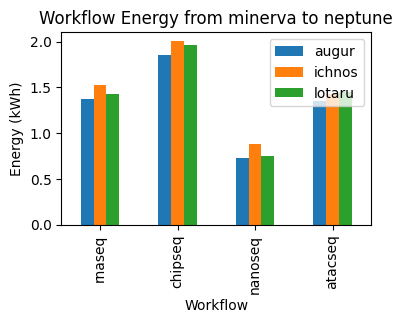

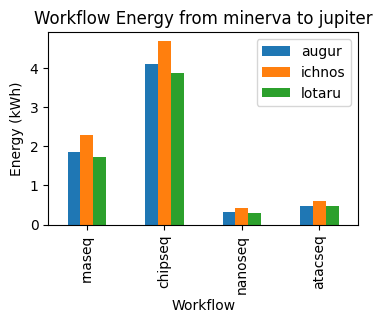

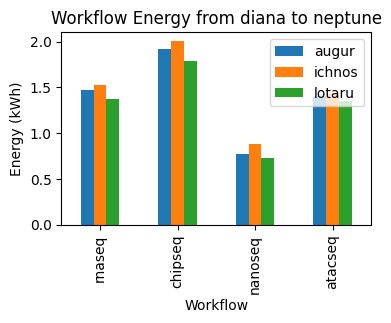

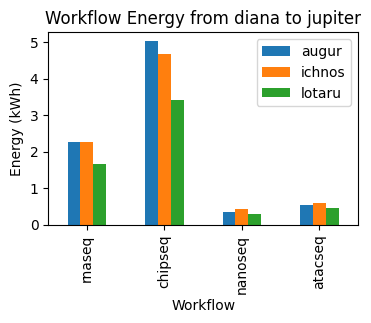

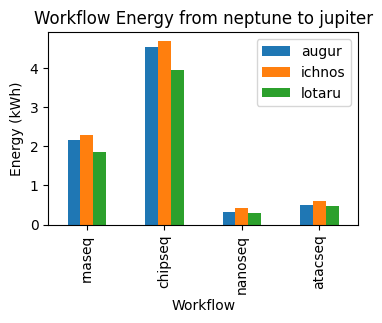

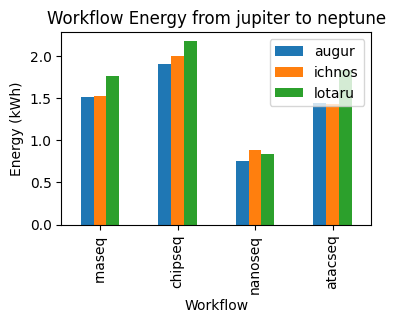

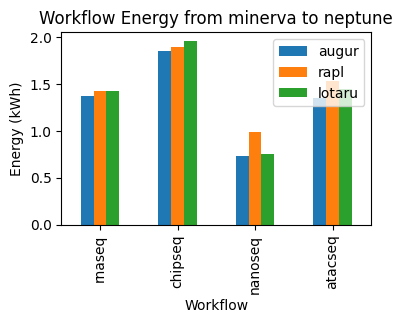

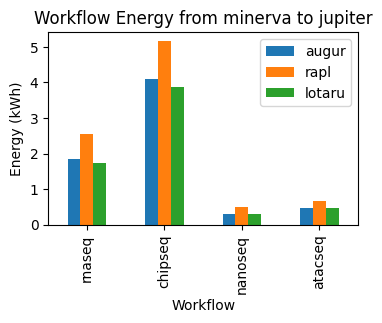

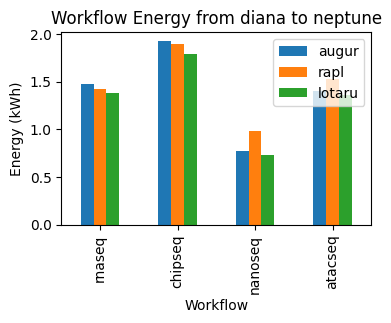

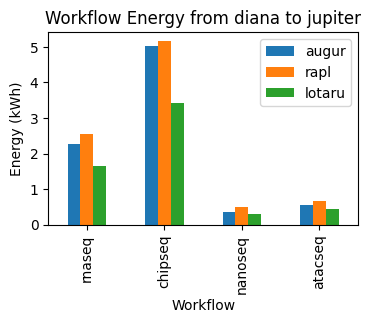

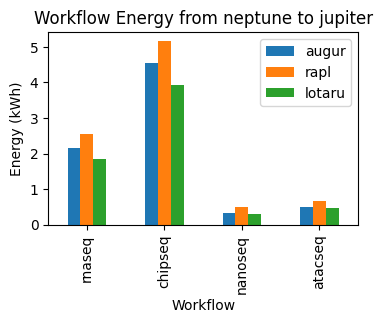

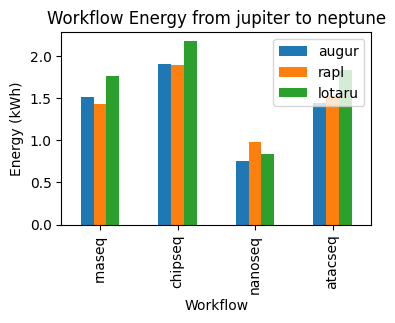

In [58]:
for key, val in grouped_comparison:
    local = paper_nodes[key[0]]
    target = paper_cluster_nodes[key[1]]
    # print(val)
    val = val.drop(['rapl'], axis=1)
    fig = val.plot.bar(x='workflow', figsize=(4,2.5))
    plt.ylabel('Energy (kWh)')
    plt.xlabel('Workflow')
    plt.title(f'Workflow Energy from {local} to {target}')
    plt.savefig(f'../images/wf-energy-pred-{local}-{target}-ichnos.pdf', dpi=300, bbox_inches='tight')
    # plt.show()

for key, val in grouped_comparison:
    local = paper_nodes[key[0]]
    target = paper_cluster_nodes[key[1]]
    # print(val)
    val = val.drop(['ichnos'], axis=1)
    fig = val.plot.bar(x='workflow', figsize=(4,2.5))
    plt.ylabel('Energy (kWh)')
    plt.xlabel('Workflow')
    plt.title(f'Workflow Energy from {local} to {target}')
    plt.savefig(f'../images/wf-energy-pred-{local}-{target}-rapl.pdf', dpi=300, bbox_inches='tight')
    # plt.show()

In [31]:
print(pred_headers)
print('===')
for _, row in res_reflections.iterrows(): # pred_headers = ['task_runtime_err', 'task_energy_err', 'wf_ichnos_err', 'wf_rapl_err', 'reflector']
    print(f'{row['workflow']} & {paper_nodes[row['local_node']]} & {paper_cluster_nodes[row['target']]} \
& {row['task_time_error']:.2f} & {row['task_energy_error']:.2f} \
& {row['task_runtime_err']:.2f} & {row['task_energy_err']:.2f} \
& {row['wf_ichnos_err']:.2f} & {row['wf_rapl_err']:.2f} \\\\')

print('===')
print('cum. task runtime error', res_reflections['task_time_error'].mean(), res_reflections['task_time_error'].std())
print('cum. task energy error', res_reflections['task_energy_error'].mean(), res_reflections['task_energy_error'].std())
print('ichnos wf energy error', res_reflections['wf_ichnos_err'].mean(), res_reflections['wf_ichnos_err'].std())
print('rapl wf energy error', res_reflections['wf_rapl_err'].mean(), res_reflections['wf_rapl_err'].std())

['workflow', 'local_node', 'target', 'task_time_error', 'task_energy_error', 'task_runtime_err', 'task_energy_err', 'wf_ichnos_err', 'wf_rapl_err', 'reflector', 'augur_e', 'ichnos_e', 'rapl_e']
===
rnaseq & jupiter & neptune & 14.42 & 23.71 & 28.14 & 69.85 & 0.55 & 6.40 \\
chipseq & jupiter & neptune & 22.71 & 17.83 & 40.35 & 62.04 & 4.84 & 0.53 \\
nanoseq & jupiter & neptune & 36.32 & 15.74 & 37.42 & 83.98 & 14.03 & 23.11 \\
atacseq & jupiter & neptune & 18.99 & 6.83 & 30.79 & 64.28 & 0.73 & 5.70 \\
rnaseq & neptune & jupiter & 11.37 & 5.67 & 27.77 & 53.68 & 5.60 & 15.23 \\
chipseq & neptune & jupiter & 3.38 & 6.49 & 22.04 & 50.97 & 3.11 & 12.04 \\
nanoseq & neptune & jupiter & 21.44 & 27.27 & 22.98 & 45.55 & 24.47 & 37.21 \\
atacseq & neptune & jupiter & 2.15 & 31.15 & 33.67 & 73.78 & 17.36 & 25.58 \\
rnaseq & diana & neptune & 11.38 & 2.54 & 25.91 & 63.98 & 3.36 & 3.39 \\
chipseq & diana & neptune & 19.20 & 13.35 & 25.63 & 50.87 & 4.01 & 1.40 \\
nanoseq & diana & neptune & 31.94 & 1

In [ ]:
# Plots of Task with Energy Prediction Error + Helper Functions
def get_marker(model_type):
    raw_type = model_type.replace('**', '').replace('REFLECT-ONLY', '').strip()
    return {
        model_type: 'o',
        'Low Variance': 's',
        'Median': 'D',
        'Weak Linear Rel.': 'p'
    }.get(raw_type, 'o')

def get_colour(model_type):
    if '**REFLECT-ONLY' in model_type:
        return 'red'
    elif '**' in model_type:
        return 'orange'
    else:
        return 'green'

def plot_task_times_with_energy_error(wf, data_df, runtime_vals, energy_vals, missing_tasks, max_length, location, details):
    workflow_types = data_df.groupby(['type']).size().reset_index(name='counts')
    no_tasks = workflow_types['counts'].sum()
    summary = ' | '.join(
        f"{row['type'].replace('**REFLECT-ONLY', ' (reflector only)').replace('**', ' (+reflector)').replace(LR, 'LR').replace(' (', '(')}: {row['counts']} ({row['counts'] / no_tasks * 100:.2f}%)"
        for _, row in workflow_types.iterrows()
    )
    print(wf, f'tasks: {no_tasks}')
    print(summary)
    print('missing', len(missing_tasks))
    print('task cumulative runtime error', f'{get_error(runtime_vals[0], runtime_vals[1]):.2f}%', runtime_vals)
    print('task cumulative energy error', f'{get_error(energy_vals[0], energy_vals[1]):.2f}%', energy_vals)
    
    tmp_df = data_df.copy()
    tmp_df['actual_t'] = tmp_df['actual_t'] / 60 # convert to minutes
    graph_df = tmp_df.groupby(['task', 'type']).agg(
        count=('type', 'size'),            # number of rows per group
        avg_error=('energy_error', 'mean'),       # average error
        avg_time=('actual_t', 'mean'),     # average time (already in minutes)
    ).reset_index()
    graph_df['colour'] = graph_df['type'].apply(lambda model_t: get_colour(model_t))
    graph_df['marker'] = graph_df['type'].apply(lambda model_t: get_marker(model_t))

    legend_items = set()
    for _, row in graph_df.iterrows():
        label = row['type'] if row['type'] not in legend_items else '_nolegend_'
        label = label.replace('**REFLECT-ONLY', ' (reflector only)').replace('**', ' (+reflector)').replace(LR, 'LR').replace(' (', '\n(')
        legend_items.add(row['type'])
        plt.scatter(row['avg_time'], row['avg_error'], c=row['colour'], s=row['count'], marker=row['marker'], label=label)
    
    plt.xlabel('task runtime (m)')
    plt.xlim([0, max_length])
    plt.ylabel('energy error (%)')
    plt.legend(loc=location)
    plt.savefig(f'../images/{wf}-task-time-energy-error-{details}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
local_profile = wf_profiles[AWS_c5d]['node_profile']
target_profile = wf_profiles[HU_40]['node_profile']

rnaseq tasks: 979
LR: 273 (27.89%) | Low Variance: 431 (44.02%) | Median: 119 (12.16%) | Weak Linear Rel.: 156 (15.93%)
missing 53
task cumulative runtime error 20.93% (246593.24150170747, 203908.31)
task cumulative energy error 12.89% (0.7920318199353766, 0.7015792285216721)


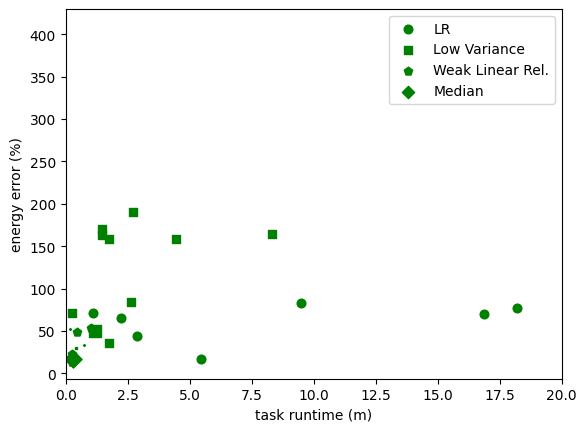

In [ ]:
# diana -> jupiter
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'rnaseq', local_profile, target_profile, (GBR, LASSO), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['rnaseq'], wf_executions[HU]['rnaseq'][1], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('rnaseq', data_df, runtime_vals, energy_vals, missing_tasks, 20, 'upper right', 'diana-jupiter')

chipseq tasks: 2059
Low Variance: 1523 (73.97%) | Median: 353 (17.14%) | Weak Linear Rel.: 183 (8.89%)
missing 298
task cumulative runtime error 36.39% (440898.77742067276, 323272.733)
task cumulative energy error 40.02% (1.9775709521999945, 1.412380579395598)


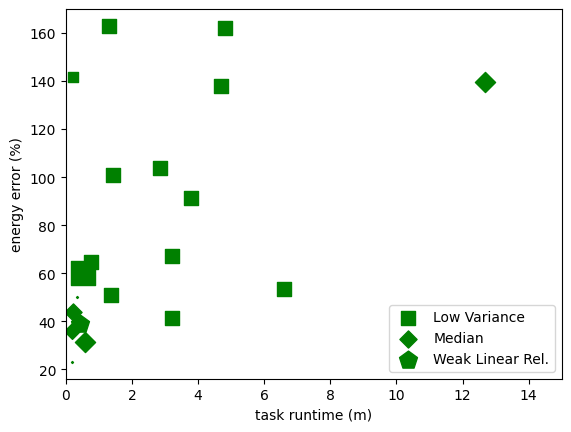

In [ ]:
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'chipseq', local_profile, target_profile, (GBR, LASSO), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['chipseq'], wf_executions[HU]['chipseq'][1], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('chipseq', data_df, runtime_vals, energy_vals, missing_tasks, 15, 'lower right', 'diana-jupiter')

nanoseq tasks: 70
LR: 51 (72.86%) | Low Variance: 6 (8.57%) | Median: 4 (5.71%) | Weak Linear Rel.: 9 (12.86%)
missing 3
task cumulative runtime error 25.49% (16366.514987753875, 13042.157)
task cumulative energy error 46.12% (0.06460796952909563, 0.044216251293112054)


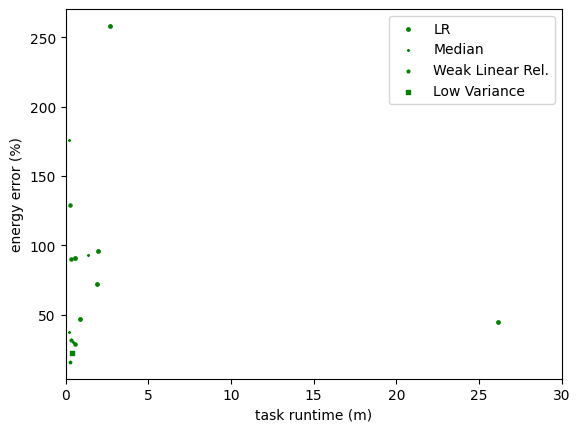

In [ ]:
# aws-metal-c5d to HU cluster execution (worst task energy estimations?)
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'nanoseq', local_profile, target_profile, (GBR, LASSO), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['nanoseq'], wf_executions[HU]['nanoseq'][1], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('nanoseq', data_df, runtime_vals, energy_vals, missing_tasks, 30, 'upper right', 'diana-jupiter')

atacseq tasks: 184
LR: 82 (44.57%) | Low Variance: 30 (16.30%) | Median: 28 (15.22%) | Weak Linear Rel.: 44 (23.91%)
missing 3
task cumulative runtime error 23.97% (28877.787182829932, 23294.569)
task cumulative energy error 78.55% (0.13248655832459788, 0.07419961765855795)


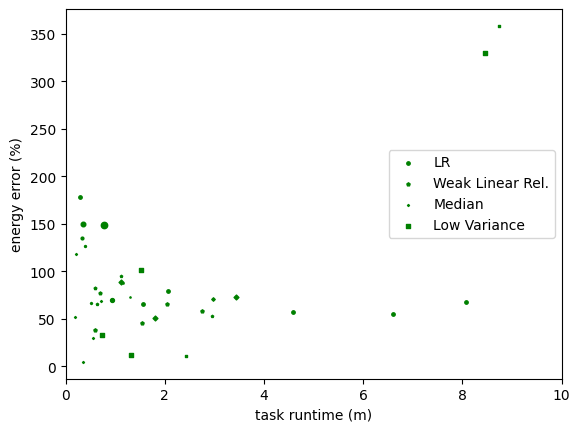

In [ ]:
# aws-metal-c5d to HU cluster execution (worst task energy estimations?)
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'atacseq', local_profile, target_profile, (GBR, LASSO), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['atacseq'], wf_executions[HU]['atacseq'][2], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('atacseq', data_df, runtime_vals, energy_vals, missing_tasks, 10, 'right', 'diana-jupiter')

Profiling Overhead

In [ ]:
def get_wf_runtime(wf_df):
    start = wf_df['start'].min()
    complete = wf_df['complete'].max()
    return (complete - start) / 1000 / 60  # return runtime in minutes

# need some df with each sample and the size of data
profiling_data = { # MiB
    # rnaseq (a, b, e)
    'sample_a': 107 + 113.7, 
    'sample_b': 111.1 + 117.9, 
    'sample_c': 95.6 + 101.4,
    'sample_d': 81.1 + 85.8,
    'sample_e': 160.8 + 170.2,
    # chipseq (f, g, j)
    'sample_f': 96.4, 
    'sample_g': 100.3,
    'sample_h': 72.9,
    'sample_i': 77.6,
    'sample_j': 129.6, 
    # nanoseq (m, l, k)
    'sample_k': 290.2 + 177.4,
    'sample_l': 232.1 + 141.8,
    'sample_m': 193.5 + 118.4,
    'sample_n': 166.1 + 101, 
    'sample_o': 145.2 + 88.3,
    # atacseq (r, q, p)
    'sample_p': 157.4 + 161.7 + 148.8 + 154.4,
    'sample_q': 125.6 + 129 + 118.6 + 123.2,
    'sample_r': 106.9 + 109.7 + 101 + 104.8, 
    'sample_s': 92.3 + 94.7 + 87.2 + 90.5,
    'sample_t': 79.3 + 81.5 + 74.9 + 77.8,
}
workflow_data = { # GiB
    'rnaseq': 1 + 1.1 + 0.8304 + 0.8869 + 1.2 + 1.3 + 1.2 + 1.3 + 1.3 + 1.4 + 1.4 + 1.5,
    'chipseq': 1 + 1.1 + 1 + 1.2 + 1.1 + 1.1 + 1.3 + 1.3 + 1,
    'nanoseq': 2.2 + 2.2 + 1 + 1.3 + 0.5272 + 2.2,
    'atacseq': 1.1 + 1.1 + 1.0 + 1.1 + 1.4 + 1.6 + 1.2 + 1.4 + 0.2059 + 0.2285 + 0.3649 + 0.3992
}

In [ ]:
prof_data = []
prof_oh_headers = ['node', 'wf', 'sample', 'data', 'full_data', 'data OH', 'time', 'full time', 'time OH']

for node, paper_node in zip([AWS_m5_4xl, AWS_c5d, GPG_18, HU_40], ['minerva', 'diana', 'neptune', 'jupiter']):
    profiling_runs = wf_profiles[node]['executions']

    for workflow in ['atacseq', 'chipseq', 'nanoseq', 'rnaseq']:
        full_wf_runtime = round(get_wf_runtime(wf_executions[GPG][workflow][1]['run']) * 4, 2)  # full workflows ran on 4 nodes
        for sample in profiling_runs[workflow].keys():
            run = profiling_runs[workflow][sample]
            mini_runtime = round(get_wf_runtime(run), 2)
            mini_size = round(profiling_data[sample] / 1000, 2)
            full_size = round(workflow_data[workflow], 2)
            data_ratio = round((mini_size / full_size) * 100, 2)
            time_ratio = round((mini_runtime / full_wf_runtime) * 100, 2)
            prof_data.append([paper_node, workflow, sample, mini_size, full_size, data_ratio, mini_runtime, full_wf_runtime, time_ratio])

prof_df = pd.DataFrame(prof_data, columns=prof_oh_headers)

In [ ]:
print('profiling overhead')
for _, row in prof_df.iloc[prof_df.groupby(['node', 'wf'])['data'].idxmax()][['node', 'wf', 'sample', 'data', 'data OH', 'time', 'time OH']].iterrows():
    print(f'{row['node']} & {row['wf']} & {row['data']} & {row['data OH']} & {row['time']} & {row['time OH']} & TODO & TODO \\\\')

profiling overhead
diana & atacseq & 0.62 & 5.59 & 18.0 & 1.86 & TODO & TODO \\
diana & chipseq & 0.13 & 1.29 & 17.53 & 1.39 & TODO & TODO \\
diana & nanoseq & 0.47 & 4.98 & 9.77 & 1.12 & TODO & TODO \\
diana & rnaseq & 0.33 & 2.29 & 34.88 & 3.45 & TODO & TODO \\
jupiter & atacseq & 0.62 & 5.59 & 15.42 & 1.59 & TODO & TODO \\
jupiter & chipseq & 0.13 & 1.29 & 17.64 & 1.39 & TODO & TODO \\
jupiter & nanoseq & 0.47 & 4.98 & 6.22 & 0.72 & TODO & TODO \\
jupiter & rnaseq & 0.33 & 2.29 & 31.07 & 3.08 & TODO & TODO \\
minerva & atacseq & 0.62 & 5.59 & 35.8 & 3.7 & TODO & TODO \\
minerva & chipseq & 0.13 & 1.29 & 26.96 & 2.13 & TODO & TODO \\
minerva & nanoseq & 0.47 & 4.98 & 14.04 & 1.62 & TODO & TODO \\
minerva & rnaseq & 0.33 & 2.29 & 57.93 & 5.73 & TODO & TODO \\
neptune & atacseq & 0.62 & 5.59 & 66.95 & 6.92 & TODO & TODO \\
neptune & chipseq & 0.13 & 1.29 & 54.05 & 4.27 & TODO & TODO \\
neptune & nanoseq & 0.47 & 4.98 & 15.69 & 1.81 & TODO & TODO \\
neptune & rnaseq & 0.33 & 2.29 & 97.5